# HemoLearn AI — Clasificador de leucocitos (5 clases)

Notebook de entrenamiento del modelo de visión que usará la app educativa **HemoLearn AI**
(flashcards, quizzes y modo laboratorio). Clasifica imágenes de **una sola célula** en
`basophil`, `eosinophil`, `lymphocyte`, `monocyte` y `neutrophil`.

> ⚠️ Herramienta **educativa**, no de diagnóstico.

**Cómo usarlo**
1. Ejecutar todo con `MODO_RAPIDO = True` (≈100 imágenes por clase, 1 época por etapa) para comprobar que corre de principio a fin. Resultados en `outputs/prueba_rapida/`.
2. Cambiar a `MODO_RAPIDO = False` y ejecutar de nuevo. Resultados en `outputs/`.

Todas las cifras de este notebook salen de la ejecución; no hay valores escritos a mano salvo los de los artículos citados.

## 1. Contexto y estado del arte

| # | Trabajo | Método | Resultado |
|---|---|---|---|
| 1 | Ramesh et al., 2012 | ML clásico, WSI privado, 5 clases | acc 93,9 % |
| 2 | Putzu et al., 2014 | SVM-RBF, ALL-IDB | acc 93,2 % |
| 3 | Prinyakupt y Pluempitiwiriyawej, 2015 | Clasificador lineal vs Naïve Bayes | ≈98 % vs ≈94 % |
| 4 | Acevedo et al., 2019 | VGG-16 / Inception-v3, PBC, 8 clases | 96,2 %; fine-tuning +10 pts vs extractor |
| 5 | Cheuque et al., 2022 | Faster R-CNN + MobileNet, 4 clases (sin basófilos) | ≈98,4 % |
| 6 | Katar y Yildirim, 2023 | ViT + Score-CAM, 5 clases | 99,40 % |
| 7 | Yin et al., 2023 | Swin vs ResNet | 99,1 % vs 95,2 %; monocitos 93,8 % |
| 8 | Dipto et al., 2023 | ViT, dataset pequeño (BCCD) | 83–85 % |
| 9 | Kukuljan et al., 2025 | LLM multimodales en PBC | F1 pond. GPT-4o 0,22 (zero-shot) / 0,74 (fine-tuning) vs 0,87 modelo específico |
| 10 | Ferber et al., 2025 | Agente con herramientas | el LLM rinde mejor orquestando modelos especializados |

**Decisiones que se derivan**
- Un LLM no clasifica: se entrena un modelo de visión específico (9, 10).
- Fine-tuning en dos etapas, no solo extractor de características (4).
- MobileNetV2 como modelo principal por ser ligero (5); ResNet18 como base CNN; DeiT-Tiny como ViT pequeño (6, 8).
- Se incluyen basófilos y se compensa el desbalance con pesos por clase.
- Métricas por clase, con atención a monocitos (7).
- Grad-CAM para explicabilidad (6, 8).
- Validación externa en otro centro (Raabin-WBC), porque la limitación más repetida es el dataset de un solo centro.

## 2. Configuración, entorno y modo de prueba

In [1]:
from pathlib import Path

# Cambiar a False para el entrenamiento completo
MODO_RAPIDO = True

# MobileNetV2 se entrena siempre (es el modelo de la app)
ENTRENAR_RESNET = True
ENTRENAR_VIT = True

SEMILLA = 42
CLASES = ['basophil', 'eosinophil', 'lymphocyte', 'monocyte', 'neutrophil']  # orden de labels.json

RUTA_PBC = Path('data/PBC_dataset_normal_DIB')
RUTA_RAABIN_A = Path('data/Raabin/TestA')    # validación externa principal (5 clases)
RUTA_RAABIN_B = Path('data/Raabin/Test-B')   # secundaria: solo linfocitos y neutrófilos

N_RAPIDO_PBC = 100      # imágenes por clase en modo rápido
N_RAPIDO_RAABIN = 20    # imágenes por clase de Raabin en modo rápido

EPOCAS_E1 = 1 if MODO_RAPIDO else 5
EPOCAS_E2 = 1 if MODO_RAPIDO else 12
PACIENCIA = 4
LR_E1, LR_E2 = 1e-3, 1e-4

UMBRAL_APP = 0.65          # umbral actual de "revisión manual"
OBJETIVO_ACC_UMBRAL = 0.99 # accuracy mínima deseada sobre las imágenes que no van a revisión (en validación)
TOLERANCIA_F1 = 0.01       # se prefiere el modelo más ligero si su F1 macro en validación está a ≤1 punto del mejor

OUT = Path('outputs/prueba_rapida') if MODO_RAPIDO else Path('outputs')

In [2]:
import os, gc, json, time, random, platform, warnings
from datetime import datetime
os.environ.setdefault('HF_HUB_DISABLE_SYMLINKS_WARNING', '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
import timm
import onnx
import onnxruntime as ort
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix)
from IPython.display import display

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)

def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def liberar():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

fijar_semilla()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USA_AMP = DEVICE.type == 'cuda'
if USA_AMP:
    prop = torch.cuda.get_device_properties(0)
    print(f'GPU: {prop.name} | memoria: {prop.total_memory / 1024**3:.2f} GB')
    # benchmark=True re-optimiza con cada tamaño de batch nuevo (≈30 s cada vez en esta GPU) y resta reproducibilidad
    torch.backends.cudnn.benchmark = False
else:
    print('No hay GPU: se usará la CPU (mucho más lento).')
print(f'Python {platform.python_version()} | torch {torch.__version__} (CUDA {torch.version.cuda}) | timm {timm.__version__}')
print(f'MODO_RAPIDO = {MODO_RAPIDO} → resultados en {OUT.as_posix()}/')

for sub in ['splits', 'figuras', 'modelos']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)

GPU: NVIDIA GeForce RTX 3050 Laptop GPU | memoria: 4.00 GB
Python 3.11.7 | torch 2.11.0+cu128 (CUDA 12.8) | timm 1.0.31
MODO_RAPIDO = True → resultados en outputs/prueba_rapida/


In [3]:
# Estilo de figuras: colores fijos por serie y rampa azul secuencial
COLORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
NOMBRE = {'mobilenetv2': 'MobileNetV2', 'resnet18': 'ResNet18', 'deit_tiny': 'DeiT-Tiny'}
COLOR_MODELO = {'mobilenetv2': COLORES[0], 'resnet18': COLORES[1], 'deit_tiny': COLORES[2]}
CORTO = {'basophil': 'Baso', 'eosinophil': 'Eos', 'lymphocyte': 'Linf', 'monocyte': 'Mono', 'neutrophil': 'Neut'}
CMAP_SEQ = LinearSegmentedColormap.from_list(
    'azul', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#104281', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'text.color': '#0b0b0b',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.titlesize': 11, 'font.size': 10, 'lines.linewidth': 2, 'legend.frameon': False,
})

## 3. Datos: inspección y mapeo de clases

- **Entrenamiento:** PBC (Acevedo et al., Mendeley Data, DOI 10.17632/snkd93bnjr.1). Se ignoran `erythroblast`, `ig` y `platelet`.
- **Validación externa principal:** Raabin-WBC **TestA** (5 clases, otro centro, otra tinción y cámara).
- **Validación externa secundaria:** Raabin-WBC **Test-B** (solo linfocitos y neutrófilos).

Raabin se usa **solo** en la evaluación final: nunca para entrenar, ajustar ni elegir umbrales. Los archivos de `data/` solo se leen.

In [4]:
MAPEO_PBC = {c: c for c in CLASES}                    # erythroblast, ig y platelet quedan fuera
MAPEO_RAABIN = {c.capitalize(): c for c in CLASES}    # 'Neutrophil' → 'neutrophil'
EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

def listar_imagenes(raiz, mapeo):
    filas, resumen = [], []
    for carpeta in sorted(p for p in raiz.iterdir() if p.is_dir()):
        todos = [f for f in carpeta.iterdir() if f.suffix.lower() in EXT]
        archivos = sorted(f for f in todos if not f.name.startswith('.'))  # p. ej. restos .DS_Store de macOS
        clase = mapeo.get(carpeta.name)
        resumen.append({'carpeta': carpeta.name, 'imágenes': len(archivos), 'ocultos ignorados': len(todos) - len(archivos),
                        'clase común': clase or '— (ignorada)'})
        if clase:
            filas += [{'ruta': f.as_posix(), 'clase': clase, 'y': CLASES.index(clase)} for f in archivos]
    return pd.DataFrame(filas), pd.DataFrame(resumen)

df_pbc, res_pbc = listar_imagenes(RUTA_PBC, MAPEO_PBC)
df_ra, res_ra = listar_imagenes(RUTA_RAABIN_A, MAPEO_RAABIN)
df_rb, res_rb = listar_imagenes(RUTA_RAABIN_B, MAPEO_RAABIN)

for titulo, res in [('PBC', res_pbc), ('Raabin TestA', res_ra), ('Raabin Test-B', res_rb)]:
    print(titulo); display(res)

for titulo, df in [('PBC', df_pbc), ('Raabin TestA', df_ra), ('Raabin Test-B', df_rb)]:
    faltan = sorted(set(CLASES) - set(df.clase))
    print(f'{titulo}: {len(df)} imágenes de las 5 clases' + (f' | sin imágenes de: {faltan}' if faltan else ''))
assert not set(CLASES) - set(df_pbc.clase), 'Falta alguna clase en PBC'
assert not set(CLASES) - set(df_ra.clase), 'Falta alguna clase en Raabin TestA'

PBC


,carpeta,imágenes,ocultos ignorados,clase común
0,basophil,1218,0,basophil
1,eosinophil,3117,0,eosinophil
2,erythroblast,1551,0,— (ignorada)
3,ig,2895,0,— (ignorada)
4,lymphocyte,1214,0,lymphocyte
5,monocyte,1420,0,monocyte
6,neutrophil,3329,1,neutrophil
7,platelet,2348,0,— (ignorada)


Raabin TestA


,carpeta,imágenes,ocultos ignorados,clase común
0,Basophil,89,0,basophil
1,Eosinophil,322,0,eosinophil
2,Lymphocyte,1034,0,lymphocyte
3,Monocyte,234,0,monocyte
4,Neutrophil,2660,0,neutrophil


Raabin Test-B


,carpeta,imágenes,ocultos ignorados,clase común
0,Lymphocyte,148,0,lymphocyte
1,Neutrophil,1971,0,neutrophil


PBC: 10298 imágenes de las 5 clases
Raabin TestA: 4339 imágenes de las 5 clases
Raabin Test-B: 2119 imágenes de las 5 clases | sin imágenes de: ['basophil', 'eosinophil', 'monocyte']


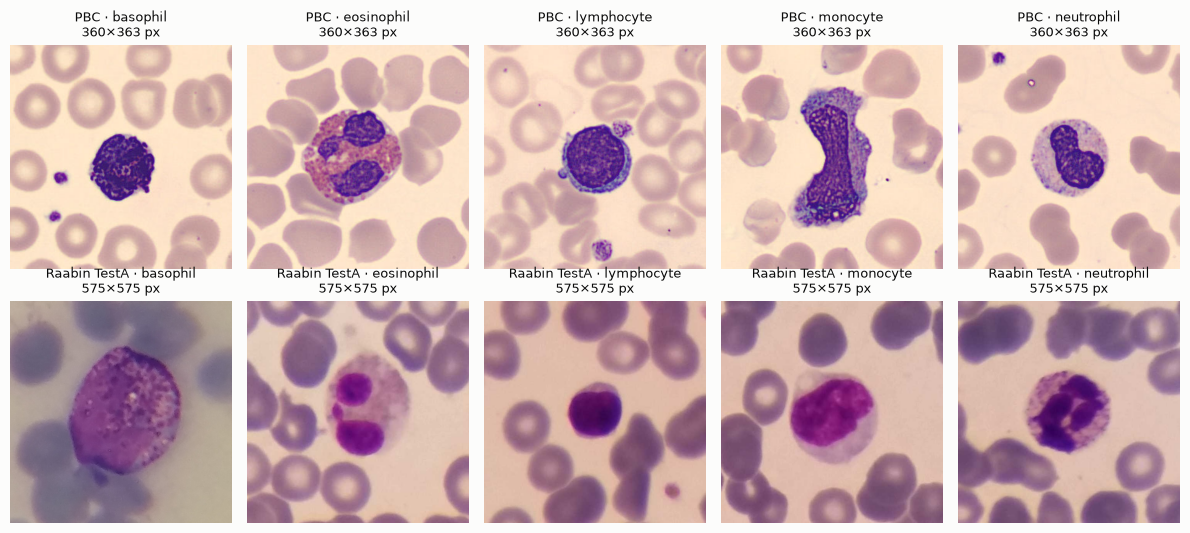

In [5]:
# Una imagen por clase en cada dataset: se aprecia el cambio de dominio (tinción, cámara, tamaño)
fig, axes = plt.subplots(2, 5, figsize=(12, 5.4))
for fila, (titulo, df) in enumerate([('PBC', df_pbc), ('Raabin TestA', df_ra)]):
    for k, c in enumerate(CLASES):
        with Image.open(df[df.clase == c].ruta.iloc[0]) as im:
            axes[fila, k].imshow(im.convert('RGB'))
            tam = im.size
        axes[fila, k].set_title(f'{titulo} · {c}\n{tam[0]}×{tam[1]} px', fontsize=9)
        axes[fila, k].axis('off')
fig.tight_layout()
fig.savefig(OUT / 'figuras' / 'ejemplos_clases.png', dpi=130)
plt.show()

## 4. Particiones estratificadas 70/15/15

División estratificada de PBC con semilla fija. En modo rápido se toma una submuestra de cada partición
(≈70/15/15 imágenes por clase) para que el test rápido sea un subconjunto del test real.

In [6]:
train_df, tmp_df = train_test_split(df_pbc, test_size=0.30, stratify=df_pbc.y, random_state=SEMILLA)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df.y, random_state=SEMILLA)

def muestra_por_clase(df, n):
    idx = [g.sample(min(n, len(g)), random_state=SEMILLA).index for _, g in df.groupby('clase')]
    return df.loc[np.concatenate(idx)]

if MODO_RAPIDO:
    train_df = muestra_por_clase(train_df, round(N_RAPIDO_PBC * 0.70))
    val_df = muestra_por_clase(val_df, round(N_RAPIDO_PBC * 0.15))
    test_df = muestra_por_clase(test_df, round(N_RAPIDO_PBC * 0.15))
    df_ra = muestra_por_clase(df_ra, N_RAPIDO_RAABIN)
    df_rb = muestra_por_clase(df_rb, N_RAPIDO_RAABIN)

train_df, val_df, test_df, df_ra, df_rb = (d.reset_index(drop=True) for d in (train_df, val_df, test_df, df_ra, df_rb))
assert not (set(train_df.ruta) & set(val_df.ruta) or set(train_df.ruta) & set(test_df.ruta) or set(val_df.ruta) & set(test_df.ruta))

for nombre_archivo, d in [('train', train_df), ('val', val_df), ('test', test_df),
                          ('raabin_testA', df_ra), ('raabin_testB', df_rb)]:
    d[['ruta', 'clase', 'y']].to_csv(OUT / 'splits' / f'{nombre_archivo}.csv', index=False)

conteo_particiones = pd.concat([
    d.assign(particion=p) for p, d in
    [('train', train_df), ('val', val_df), ('test', test_df), ('raabin_testA', df_ra), ('raabin_testB', df_rb)]
]).pipe(lambda d: pd.crosstab(d.clase, d.particion, margins=True, margins_name='total'))
conteo_particiones = conteo_particiones[['train', 'val', 'test', 'raabin_testA', 'raabin_testB', 'total']]
display(conteo_particiones)
print(f'Listas guardadas en {(OUT / "splits").as_posix()}/')

particion,train,val,test,raabin_testA,raabin_testB,total
clase,,,,,,
basophil,70,15,15,20,0,120
eosinophil,70,15,15,20,0,120
lymphocyte,70,15,15,20,20,140
monocyte,70,15,15,20,0,120
neutrophil,70,15,15,20,20,140
total,350,75,75,100,40,640


Listas guardadas en outputs/prueba_rapida/splits/


## 5. Preprocesamiento (idéntico al de la app)

Redimensionado directo a 224×224 (sin recorte, bilineal) → RGB → escala a [0, 1] → normalización ImageNet →
tensor `[1, 3, 224, 224]` NCHW float32. El aumento de datos se aplica **solo** en entrenamiento.

In [7]:
TAM = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

tf_eval = transforms.Compose([
    transforms.Resize((TAM, TAM), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
tf_train = transforms.Compose([
    transforms.Resize((TAM, TAM), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

PREPROCESAMIENTO = {
    'input_name': 'input',
    'input_shape': [1, 3, TAM, TAM],
    'layout': 'NCHW',
    'dtype': 'float32',
    'color': 'RGB',
    'resize': {'size': [TAM, TAM], 'mode': 'directo, sin recorte ni relleno', 'interpolation': 'bilinear'},
    'scale': 'pixel / 255.0 → [0, 1]',
    'mean': MEAN,
    'std': STD,
    'formula': '(pixel / 255 - mean[c]) / std[c]',
    'output_name': 'logits',
    'output_shape': [1, len(CLASES)],
    'labels': CLASES,
    'aumento_solo_entrenamiento': {
        'flip_horizontal': 0.5, 'flip_vertical': 0.5, 'rotacion_grados': 20,
        'color_jitter': {'brightness': 0.2, 'contrast': 0.2, 'saturation': 0.2, 'hue': 0.02},
    },
}
with open(OUT / 'preprocessing.json', 'w', encoding='utf-8') as f:
    json.dump(PREPROCESAMIENTO, f, indent=2, ensure_ascii=False)

In [8]:
class CelulasDataset(Dataset):
    def __init__(self, df, tf):
        self.rutas, self.y, self.tf = df.ruta.tolist(), df.y.tolist(), tf
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        with Image.open(self.rutas[i]) as im:
            img = im.convert('RGB')
        return self.tf(img), self.y[i]

GEN = torch.Generator().manual_seed(SEMILLA)  # un solo generador: el orden cambia en cada época pero es reproducible

def hacer_loader(df, tf, bs, barajar=False):
    return DataLoader(CelulasDataset(df, tf), batch_size=bs, shuffle=barajar, num_workers=0,
                      pin_memory=USA_AMP, generator=GEN if barajar else None)

# Comprobación: el preprocesado de torchvision coincide con una versión "a mano" como la de la app
with Image.open(train_df.ruta.iloc[0]) as im:
    img = im.convert('RGB')
x_tv = tf_eval(img).numpy()
arr = np.asarray(img.resize((TAM, TAM), Image.BILINEAR), dtype=np.float32) / 255.0
x_app = ((arr - np.array(MEAN, dtype=np.float32)) / np.array(STD, dtype=np.float32)).transpose(2, 0, 1)
dif = float(np.abs(x_tv - x_app).max())
print(f'Forma del tensor: {list(tf_eval(img).unsqueeze(0).shape)} | diferencia máxima torchvision vs manual: {dif:.2e}')
assert x_tv.shape == (3, TAM, TAM) and dif < 1e-5

Forma del tensor: [1, 3, 224, 224] | diferencia máxima torchvision vs manual: 0.00e+00


## 6. Modelos y fine-tuning por etapas

| Modelo | timm | Batch | Etapa 2: se descongela |
|---|---|---|---|
| MobileNetV2 (app) | `mobilenetv2_100.ra_in1k` | 64 | últimos 3 grupos de bloques + `conv_head` |
| ResNet18 (base CNN) | `resnet18.tv_in1k` | 48 | `layer3` y `layer4` |
| DeiT-Tiny (ViT) | `deit_tiny_patch16_224.fb_in1k` | 32 | últimos 4 bloques + `norm` |

Se usa DeiT-Tiny en lugar de `vit_tiny` porque fue preentrenado con la media y desviación de ImageNet,
igual que el preprocesado fijo de la app (los `vit_tiny` de timm usan 0,5/0,5).

- **Etapa 1:** backbone congelado, solo la cabeza (AdamW, lr 1e-3).
- **Etapa 2:** últimos bloques descongelados (lr 1e-4, coseno, early stopping con paciencia 4).
- Pérdida con pesos por clase; se guarda el mejor estado según F1 macro en validación.
- Precisión mixta en CUDA; si aparece *CUDA out of memory*, el batch se reduce a la mitad y se repite la época.

In [9]:
MODELOS = {
    'mobilenetv2': dict(timm='mobilenetv2_100.ra_in1k', batch=64,
                        descongelar=lambda m: [m.blocks[4:], m.conv_head, m.bn2]),
    'resnet18': dict(timm='resnet18.tv_in1k', batch=48,
                     descongelar=lambda m: [m.layer3, m.layer4]),
    'deit_tiny': dict(timm='deit_tiny_patch16_224.fb_in1k', batch=32,
                      descongelar=lambda m: [m.blocks[-4:], m.norm]),
}
MODELOS_ACTIVOS = ['mobilenetv2'] + (['resnet18'] if ENTRENAR_RESNET else []) + (['deit_tiny'] if ENTRENAR_VIT else [])

conteo_train = np.bincount(train_df.y, minlength=len(CLASES))
PESOS = torch.tensor(len(train_df) / (len(CLASES) * conteo_train), dtype=torch.float32)
print('Pesos por clase:', {c: round(float(w), 3) for c, w in zip(CLASES, PESOS)})

def crear_modelo(nombre, preentrenado=True):
    m = timm.create_model(MODELOS[nombre]['timm'], pretrained=preentrenado, num_classes=len(CLASES))
    cfg = m.pretrained_cfg
    if preentrenado and not (np.allclose(cfg['mean'], MEAN) and np.allclose(cfg['std'], STD)):
        warnings.warn(f'{nombre}: el preentrenamiento usó otra normalización ({cfg["mean"]}, {cfg["std"]})')
    # Cabeza con pesos pequeños: timm inicia la de MobileNetV2 con ±1/√5 y los logits arrancan enormes
    cabeza = m.get_classifier()
    nn.init.normal_(cabeza.weight, std=0.01)
    nn.init.zeros_(cabeza.bias)
    return m

def cargar_modelo(nombre):
    m = crear_modelo(nombre, preentrenado=False)
    m.load_state_dict(torch.load(OUT / 'modelos' / f'{nombre}.pt', map_location='cpu', weights_only=True))
    return m.eval()

def preparar_etapa(model, nombre, etapa):
    for p in model.parameters():
        p.requires_grad = False
    modulos = [model.get_classifier()] + (MODELOS[nombre]['descongelar'](model) if etapa == 2 else [])
    for m in modulos:
        for p in m.parameters():
            p.requires_grad = True
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def modo_entrenamiento(model):
    model.train()
    for m in model.modules():  # las BatchNorm congeladas conservan sus estadísticas
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def softmax(z):
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(z - z.max(1, keepdims=True))
    return e / e.sum(1, keepdims=True)

def entrenar_epoca(model, loader, opt, scaler, crit):
    modo_entrenamiento(model)
    total, n = 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USA_AMP):
            loss = crit(model(x), y)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.inference_mode()
def predecir(model, loader, amp=USA_AMP):
    model.eval()
    L, Y = [], []
    for x, y in loader:
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=amp):
            out = model(x.to(DEVICE, non_blocking=True))
        L.append(out.float().cpu()); Y.append(y)
    return torch.cat(L).numpy(), torch.cat(Y).numpy()

Pesos por clase: {'basophil': 1.0, 'eosinophil': 1.0, 'lymphocyte': 1.0, 'monocyte': 1.0, 'neutrophil': 1.0}


In [10]:
def entrenar_modelo(nombre):
    bs = MODELOS[nombre]['batch']
    fijar_semilla(); GEN.manual_seed(SEMILLA)
    model = crear_modelo(nombre).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=PESOS.to(DEVICE))
    scaler = torch.amp.GradScaler('cuda', enabled=USA_AMP)
    hist, mejor = [], {'f1': -1.0}
    t0 = time.time()

    for etapa, n_ep, lr in [(1, EPOCAS_E1, LR_E1), (2, EPOCAS_E2, LR_E2)]:
        n_entr = preparar_etapa(model, nombre, etapa)
        opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=0.01)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=n_ep) if etapa == 2 else None
        print(f'[{NOMBRE[nombre]}] etapa {etapa}: {n_entr / 1e6:.2f} M parámetros entrenables, lr={lr}, batch={bs}')
        sin_mejora = 0
        for _ in range(n_ep):
            te = time.time()
            while True:
                try:
                    loss = entrenar_epoca(model, hacer_loader(train_df, tf_train, bs, barajar=True), opt, scaler, crit)
                    logits, y = predecir(model, hacer_loader(val_df, tf_eval, bs))
                    break
                except torch.OutOfMemoryError:
                    pass
                # fuera del except para que se liberen los tensores del error
                opt.zero_grad(set_to_none=True); liberar()
                if bs == 1:
                    raise RuntimeError('CUDA out of memory incluso con batch 1')
                bs = max(1, bs // 2)
                print(f'  CUDA out of memory → batch reducido a {bs}; se repite la época')

            pred = logits.argmax(1)
            acc, f1 = accuracy_score(y, pred), f1_score(y, pred, average='macro')
            lr_actual = opt.param_groups[0]['lr']
            if sched:
                sched.step()
            hist.append(dict(modelo=nombre, etapa=etapa, epoca=len(hist) + 1, loss_train=loss, acc_val=acc,
                             f1_val=f1, lr=lr_actual, batch=bs, segundos=time.time() - te))
            mejora = f1 > mejor['f1']
            if mejora:
                mejor = {'f1': f1, 'epoca': len(hist), 'etapa': etapa,
                         'estado': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
                sin_mejora = 0
            else:
                sin_mejora += 1
            print(f'  época {len(hist):2d} (E{etapa}) loss={loss:.4f} acc_val={acc:.4f} F1_val={f1:.4f}'
                  f'{"  ★" if mejora else ""}  [{time.time() - te:.0f} s]')
            if etapa == 2 and sin_mejora >= PACIENCIA:
                print(f'  early stopping: {PACIENCIA} épocas sin mejorar el F1 macro de validación')
                break

    tiempo = time.time() - t0
    torch.save(mejor['estado'], OUT / 'modelos' / f'{nombre}.pt')
    print(f'  → mejor F1 macro val = {mejor["f1"]:.4f} (época {mejor["epoca"]}, etapa {mejor["etapa"]}) | '
          f'tiempo total {tiempo / 60:.1f} min')
    del model, opt, scaler, mejor['estado']
    return dict(historial=hist, tiempo_entrenamiento_s=tiempo, batch_final=bs, mejor_epoca=mejor['epoca'],
                mejor_etapa=mejor['etapa'], f1_val_mejor=mejor['f1'])

RESULTADOS_ENT = {}
for nombre in MODELOS_ACTIVOS:
    RESULTADOS_ENT[nombre] = entrenar_modelo(nombre)
    liberar()

[MobileNetV2] etapa 1: 0.01 M parámetros entrenables, lr=0.001, batch=64


  época  1 (E1) loss=1.5799 acc_val=0.3200 F1_val=0.2714  ★  [37 s]
[MobileNetV2] etapa 2: 1.99 M parámetros entrenables, lr=0.0001, batch=64


  época  2 (E2) loss=1.5599 acc_val=0.4133 F1_val=0.3845  ★  [26 s]
  → mejor F1 macro val = 0.3845 (época 2, etapa 2) | tiempo total 1.1 min


[ResNet18] etapa 1: 0.00 M parámetros entrenables, lr=0.001, batch=48


  época  1 (E1) loss=1.6101 acc_val=0.4000 F1_val=0.3169  ★  [8 s]
[ResNet18] etapa 2: 10.50 M parámetros entrenables, lr=0.0001, batch=48


  época  2 (E2) loss=1.4201 acc_val=0.6667 F1_val=0.6148  ★  [8 s]
  → mejor F1 macro val = 0.6148 (época 2, etapa 2) | tiempo total 0.3 min


[DeiT-Tiny] etapa 1: 0.00 M parámetros entrenables, lr=0.001, batch=32


  época  1 (E1) loss=1.5268 acc_val=0.3867 F1_val=0.3253  ★  [8 s]
[DeiT-Tiny] etapa 2: 1.78 M parámetros entrenables, lr=0.0001, batch=32


  época  2 (E2) loss=1.2300 acc_val=0.7867 F1_val=0.7736  ★  [8 s]
  → mejor F1 macro val = 0.7736 (época 2, etapa 2) | tiempo total 0.3 min


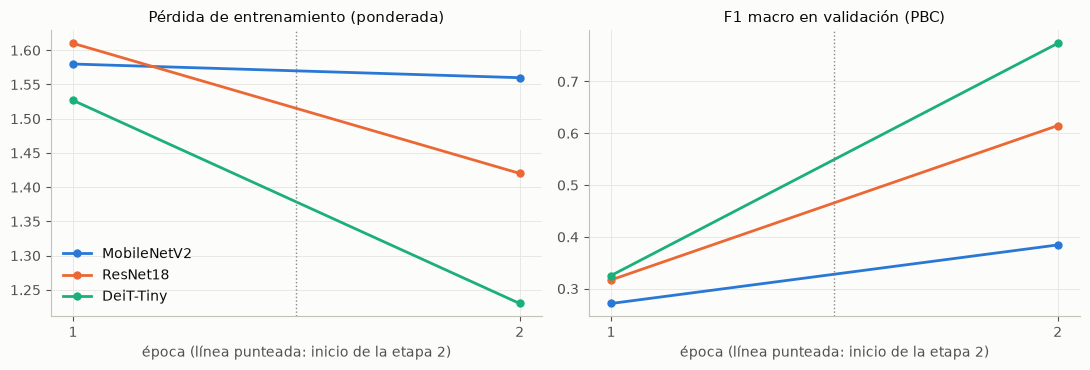

In [11]:
hist_df = pd.concat([pd.DataFrame(r['historial']) for r in RESULTADOS_ENT.values()], ignore_index=True)
hist_df.to_csv(OUT / 'historial_entrenamiento.csv', index=False)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for n, g in hist_df.groupby('modelo', sort=False):
    a1.plot(g.epoca, g.loss_train, marker='o', ms=5, color=COLOR_MODELO[n], label=NOMBRE[n])
    a2.plot(g.epoca, g.f1_val, marker='o', ms=5, color=COLOR_MODELO[n], label=NOMBRE[n])
for a in (a1, a2):
    a.axvline(EPOCAS_E1 + 0.5, color='#8a8984', ls=':', lw=1)
    a.set_xlabel('época (línea punteada: inicio de la etapa 2)')
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
a1.set_title('Pérdida de entrenamiento (ponderada)')
a2.set_title('F1 macro en validación (PBC)')
a1.legend(loc='best')
fig.tight_layout()
fig.savefig(OUT / 'figuras' / 'curvas_entrenamiento.png', dpi=150)
plt.show()

### 6.1 Selección del modelo final (solo con validación de PBC)

Se elige el modelo **más ligero** cuyo F1 macro en validación esté a ≤ `TOLERANCIA_F1` del mejor.
El test de PBC y Raabin no intervienen en la elección.

In [12]:
N_PARAMS = {n: sum(p.numel() for p in crear_modelo(n, preentrenado=False).parameters()) for n in RESULTADOS_ENT}
seleccion = pd.DataFrame([{'modelo': n, 'F1 macro val': r['f1_val_mejor'], 'parámetros (M)': N_PARAMS[n] / 1e6,
                           'mejor época': r['mejor_epoca'], 'batch final': r['batch_final'],
                           'entrenamiento (min)': r['tiempo_entrenamiento_s'] / 60}
                          for n, r in RESULTADOS_ENT.items()]).set_index('modelo')
display(seleccion.round(4))

MEJOR_VAL = seleccion['F1 macro val'].idxmax()
candidatos = seleccion[seleccion['F1 macro val'] >= seleccion['F1 macro val'].max() - TOLERANCIA_F1]
MODELO_FINAL = candidatos['parámetros (M)'].idxmin()
print(f'Mejor F1 en validación: {NOMBRE[MEJOR_VAL]} | Modelo final para la app: {NOMBRE[MODELO_FINAL]}')

,F1 macro val,parámetros (M),mejor época,batch final,entrenamiento (min)
modelo,,,,,
mobilenetv2,0.3845,2.2303,2,64,1.0575
resnet18,0.6148,11.1791,2,48,0.2753
deit_tiny,0.7736,5.5254,2,32,0.2792


Mejor F1 en validación: DeiT-Tiny | Modelo final para la app: DeiT-Tiny


## 7. Evaluación: test de PBC y validación externa (Raabin)

Se evalúa cada modelo **una sola vez** en el test de PBC, en Raabin TestA y en Raabin Test-B, en float32
(igual que el modelo exportado). En Test-B solo existen linfocitos y neutrófilos: se reportan recall/F1
de esas dos clases y el % de imágenes asignadas a clases ausentes.

In [13]:
def pares_confundidos(cm, top=5):
    filas = cm.sum(1)
    pares = [dict(real=CLASES[i], predicha=CLASES[j], n=int(cm[i, j]), pct_de_la_clase_real=100 * cm[i, j] / filas[i])
             for i in range(len(CLASES)) for j in range(len(CLASES)) if i != j and cm[i, j] > 0]
    return sorted(pares, key=lambda d: -d['pct_de_la_clase_real'])[:top]

def metricas(logits, y):
    p = softmax(logits); pred = p.argmax(1)
    etiquetas = list(range(len(CLASES)))
    presentes = sorted(set(y.tolist()))
    cm = confusion_matrix(y, pred, labels=etiquetas)
    prec, rec, f1, sop = precision_recall_fscore_support(y, pred, labels=etiquetas, zero_division=0)
    por_clase = {}
    for k, c in enumerate(CLASES):
        if sop[k] == 0:
            continue
        auc = float(roc_auc_score(y == k, p[:, k])) if sop[k] < len(y) else None
        por_clase[c] = dict(precision=float(prec[k]), recall=float(rec[k]), f1=float(f1[k]), soporte=int(sop[k]), auc_ovr=auc)
    r = dict(n=int(len(y)), accuracy=float(accuracy_score(y, pred)), clases_presentes=[CLASES[k] for k in presentes],
             por_clase=por_clase, matriz_confusion=cm.tolist(),
             predicciones_por_clase=dict(zip(CLASES, np.bincount(pred, minlength=len(CLASES)).tolist())),
             pares_mas_confundidos=pares_confundidos(cm))
    if len(presentes) == len(CLASES):
        r.update(f1_macro=float(f1_score(y, pred, average='macro')),
                 f1_ponderado=float(f1_score(y, pred, average='weighted')),
                 auc_ovr_macro=float(roc_auc_score(y, p, multi_class='ovr', labels=etiquetas)))
    else:
        r.update(f1_macro_clases_presentes=float(f1_score(y, pred, labels=presentes, average='macro')),
                 pct_predicho_en_clases_ausentes=float(100 * np.isin(pred, presentes, invert=True).mean()))
    return r

def medir_inferencia_ms(model, device, n, calentamiento=10):
    model = model.to(device).eval()
    x = torch.randn(1, 3, TAM, TAM, device=device)
    sync = torch.cuda.synchronize if device.type == 'cuda' else (lambda: None)
    with torch.inference_mode():
        for _ in range(calentamiento):
            model(x)
        sync(); t = time.perf_counter()
        for _ in range(n):
            model(x)
        sync()
    return (time.perf_counter() - t) / n * 1000

CONJUNTOS = {'val_pbc': val_df, 'test_pbc': test_df, 'raabin_testA': df_ra, 'raabin_testB': df_rb}
N_TIEMPO = 20 if MODO_RAPIDO else 100
LOGITS, METRICAS, EFICIENCIA = {}, {}, {}

for nombre in RESULTADOS_ENT:
    model = cargar_modelo(nombre).to(DEVICE)
    bs = RESULTADOS_ENT[nombre]['batch_final']
    LOGITS[nombre] = {k: predecir(model, hacer_loader(d, tf_eval, bs), amp=False) for k, d in CONJUNTOS.items()}
    METRICAS[nombre] = {k: metricas(*v) for k, v in LOGITS[nombre].items()}
    EFICIENCIA[nombre] = dict(
        parametros=N_PARAMS[nombre],
        tamano_mb=os.path.getsize(OUT / 'modelos' / f'{nombre}.pt') / 1024**2,
        ms_gpu=medir_inferencia_ms(model, DEVICE, N_TIEMPO) if USA_AMP else None,
        ms_cpu=medir_inferencia_ms(model, torch.device('cpu'), N_TIEMPO),
    )
    print(f'{NOMBRE[nombre]}: evaluado')
    del model; liberar()

MobileNetV2: evaluado


ResNet18: evaluado


DeiT-Tiny: evaluado


In [14]:
def fila_modelo(n):
    t, a, b = (METRICAS[n][k] for k in ['test_pbc', 'raabin_testA', 'raabin_testB'])
    e = EFICIENCIA[n]
    return {
        'modelo': NOMBRE[n],
        'parámetros (M)': e['parametros'] / 1e6, 'tamaño (MB)': e['tamano_mb'],
        'entrenamiento (min)': RESULTADOS_ENT[n]['tiempo_entrenamiento_s'] / 60,
        'F1 macro val PBC (%)': 100 * RESULTADOS_ENT[n]['f1_val_mejor'],
        'PBC acc (%)': 100 * t['accuracy'], 'PBC F1 macro (%)': 100 * t['f1_macro'],
        'PBC F1 pond. (%)': 100 * t['f1_ponderado'], 'PBC AUC': t['auc_ovr_macro'],
        'TestA acc (%)': 100 * a['accuracy'], 'TestA F1 macro (%)': 100 * a['f1_macro'],
        'TestA F1 pond. (%)': 100 * a['f1_ponderado'], 'TestA AUC': a['auc_ovr_macro'],
        'caída acc PBC→TestA (pts)': 100 * (t['accuracy'] - a['accuracy']),
        'caída F1 macro PBC→TestA (pts)': 100 * (t['f1_macro'] - a['f1_macro']),
        'Test-B acc (%)': 100 * b['accuracy'], 'Test-B F1 Linf+Neut (%)': 100 * b['f1_macro_clases_presentes'],
        'Test-B % a clases ausentes': b['pct_predicho_en_clases_ausentes'],
        'GPU ms/img': e['ms_gpu'], 'CPU ms/img': e['ms_cpu'],
    }

TABLA_MODELOS = pd.DataFrame([fila_modelo(n) for n in METRICAS]).set_index('modelo')
TABLA_MODELOS.to_csv(OUT / 'tabla_modelos.csv')
print('Tabla 1 · Comparación de modelos (PBC test y Raabin)')
display(TABLA_MODELOS.T.round(3))

Tabla 1 · Comparación de modelos (PBC test y Raabin)


modelo,MobileNetV2,ResNet18,DeiT-Tiny
parámetros (M),2.230,11.179,5.525
tamaño (MB),8.728,42.716,21.121
entrenamiento (min),1.058,0.275,0.279
F1 macro val PBC (%),38.446,61.480,77.364
PBC acc (%),48.000,65.333,77.333
PBC F1 macro (%),47.723,61.861,75.313
PBC F1 pond. (%),47.723,61.861,75.313
PBC AUC,0.872,0.945,0.942
TestA acc (%),30.000,45.000,40.000
TestA F1 macro (%),23.725,40.103,32.310


In [15]:
# Métricas por clase: precision / recall / F1 en PBC test y Raabin TestA
filas = []
for n in METRICAS:
    for ds, etiqueta in [('test_pbc', 'PBC test'), ('raabin_testA', 'Raabin TestA'), ('raabin_testB', 'Raabin Test-B')]:
        for c, m in METRICAS[n][ds]['por_clase'].items():
            filas.append({'modelo': NOMBRE[n], 'conjunto': etiqueta, 'clase': c, 'precision': 100 * m['precision'],
                          'recall': 100 * m['recall'], 'F1': 100 * m['f1'], 'AUC': m['auc_ovr'], 'n': m['soporte']})
POR_CLASE = pd.DataFrame(filas)
POR_CLASE.to_csv(OUT / 'metricas_por_clase.csv', index=False)
display(POR_CLASE.pivot_table(index='clase', columns=['conjunto', 'modelo'], values='F1').round(1)
        .reindex(CLASES).dropna(axis=1, how='all'))

for n in METRICAS:
    a, t = METRICAS[n]['raabin_testA']['por_clase'], METRICAS[n]['test_pbc']['por_clase']
    peor = min(a, key=lambda c: a[c]['f1'])
    print(f'{NOMBRE[n]}: monocitos F1 {100 * t["monocyte"]["f1"]:.1f} (PBC) → {100 * a["monocyte"]["f1"]:.1f} (TestA) | '
          f'clase más débil en TestA: {peor} ({100 * a[peor]["f1"]:.1f})')

conjunto    PBC test                      Raabin Test-B                      Raabin TestA                     
modelo     DeiT-Tiny MobileNetV2 ResNet18     DeiT-Tiny MobileNetV2 ResNet18    DeiT-Tiny MobileNetV2 ResNet18
clase                                                                                                         
basophil        96.8        54.5     74.3           NaN         NaN      NaN          8.7         0.0     41.0
eosinophil      50.0        42.1     20.0           NaN         NaN      NaN          0.0        16.7      0.0
lymphocyte      71.0        47.6     76.9          66.7         0.0      0.0         50.6        26.1     87.2
monocyte        76.5        55.3     66.7           NaN         NaN      NaN         30.0        31.4     20.0
neutrophil      82.4        39.0     71.4           9.5        18.2     73.9         72.2        44.4     52.3

MobileNetV2: monocitos F1 55.3 (PBC) → 31.4 (TestA) | clase más débil en TestA: basophil (0.0)
ResNet18: monocitos F1 66.7 (PBC) → 20.0 (TestA) | clase más débil en TestA: eosinophil (0.0)
DeiT-Tiny: monocitos F1 76.5 (PBC) → 30.0 (TestA) | clase más débil en TestA: eosinophil (0.0)


Pares más confundidos (% de la clase real que se asigna a la predicha)
  MobileNetV2  test_pbc      Baso→Mono 53.3% (n=8); Linf→Neut 53.3% (n=8); Eos→Neut 46.7% (n=7)
  MobileNetV2  raabin_testA  Baso→Mono 90.0% (n=18); Linf→Neut 80.0% (n=16); Eos→Mono 70.0% (n=14)
  MobileNetV2  raabin_testB  Neut→Mono 85.0% (n=17); Linf→Mono 80.0% (n=16); Linf→Eos 20.0% (n=4)
  ResNet18     test_pbc      Eos→Neut 73.3% (n=11); Linf→Baso 33.3% (n=5); Mono→Eos 20.0% (n=3)
  ResNet18     raabin_testA  Eos→Neut 85.0% (n=17); Mono→Baso 40.0% (n=8); Mono→Neut 30.0% (n=6)
  ResNet18     raabin_testB  Linf→Neut 45.0% (n=9); Linf→Baso 30.0% (n=6); Linf→Mono 25.0% (n=5)
  DeiT-Tiny    test_pbc      Eos→Neut 26.7% (n=4); Eos→Linf 20.0% (n=3); Linf→Mono 20.0% (n=3)
  DeiT-Tiny    raabin_testA  Eos→Linf 95.0% (n=19); Baso→Mono 65.0% (n=13); Mono→Linf 45.0% (n=9)
  DeiT-Tiny    raabin_testB  Neut→Linf 70.0% (n=14); Neut→Mono 25.0% (n=5); Linf→Mono 15.0% (n=3)


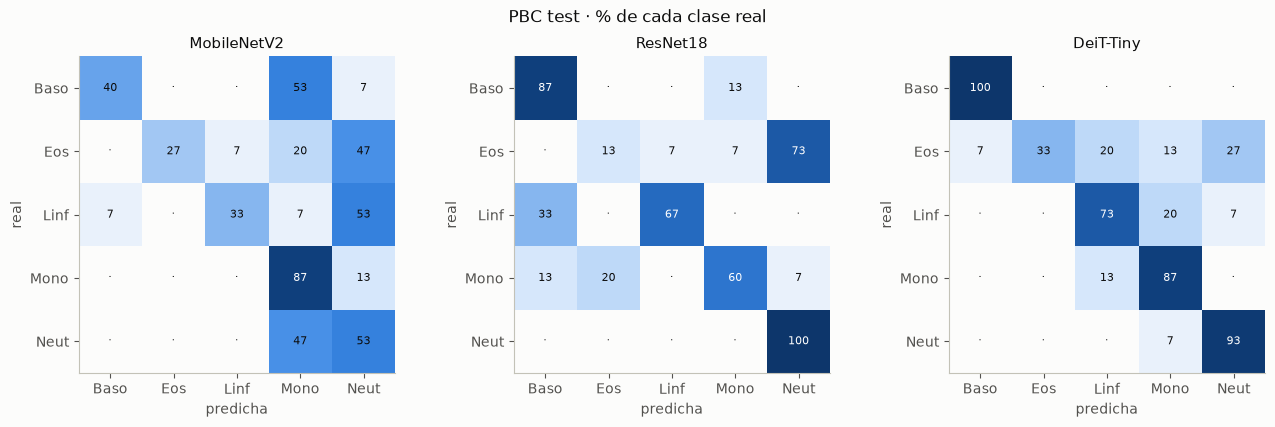

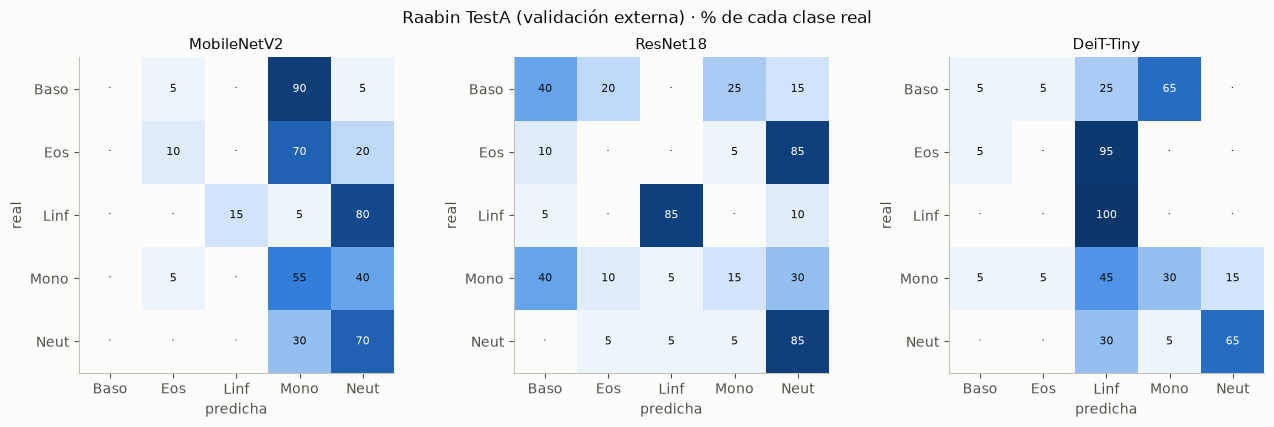

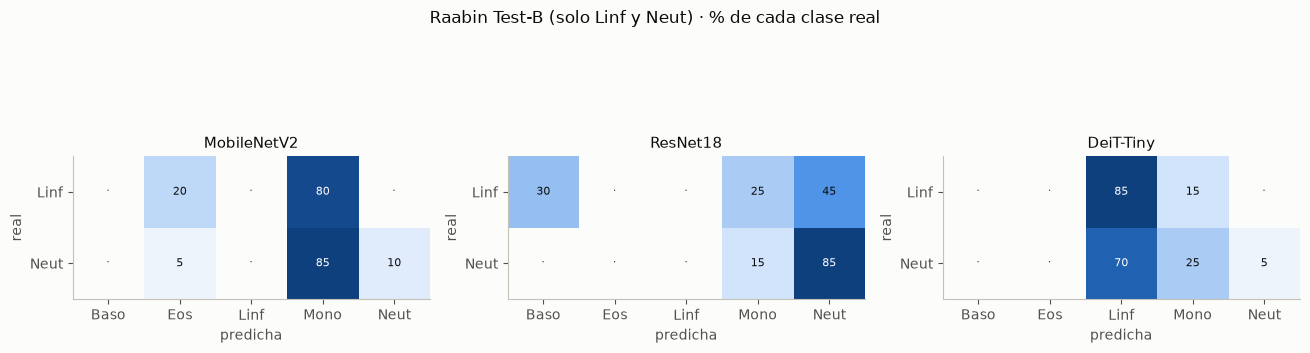

In [16]:
print('Pares más confundidos (% de la clase real que se asigna a la predicha)')
for n in METRICAS:
    for ds in ['test_pbc', 'raabin_testA', 'raabin_testB']:
        pares = METRICAS[n][ds]['pares_mas_confundidos'][:3]
        texto = '; '.join(f'{CORTO[p["real"]]}→{CORTO[p["predicha"]]} {p["pct_de_la_clase_real"]:.1f}% (n={p["n"]})'
                          for p in pares) or 'sin confusiones'
        print(f'  {NOMBRE[n]:12s} {ds:13s} {texto}')

def dibujar_confusion(ds, titulo, archivo):
    modelos = list(METRICAS)
    fig, axes = plt.subplots(1, len(modelos), figsize=(4.4 * len(modelos), 4.2), squeeze=False)
    for ax, n in zip(axes[0], modelos):
        cm = np.array(METRICAS[n][ds]['matriz_confusion'], dtype=float)
        filas = cm.sum(1) > 0
        cmn = cm[filas] / cm[filas].sum(1, keepdims=True)
        ax.imshow(cmn, cmap=CMAP_SEQ, vmin=0, vmax=1)
        for i in range(cmn.shape[0]):
            for j in range(cmn.shape[1]):
                v = cmn[i, j]
                ax.text(j, i, f'{100 * v:.0f}' if v >= 0.005 else '·', ha='center', va='center', fontsize=8,
                        color='#ffffff' if v > 0.55 else '#0b0b0b')
        ax.set_xticks(range(len(CLASES)), [CORTO[c] for c in CLASES])
        ax.set_yticks(range(int(filas.sum())), [CORTO[c] for c, f in zip(CLASES, filas) if f])
        ax.set_xlabel('predicha'); ax.set_ylabel('real'); ax.set_title(NOMBRE[n]); ax.grid(False)
    fig.suptitle(f'{titulo} · % de cada clase real')
    fig.tight_layout()
    fig.savefig(OUT / 'figuras' / archivo, dpi=150)
    plt.show()

dibujar_confusion('test_pbc', 'PBC test', 'confusion_pbc_test.png')
dibujar_confusion('raabin_testA', 'Raabin TestA (validación externa)', 'confusion_raabin_testA.png')
dibujar_confusion('raabin_testB', 'Raabin Test-B (solo Linf y Neut)', 'confusion_raabin_testB.png')

## 8. Umbral de confianza y calibración

La app marca **revisión manual** si `p_max < 0.65`. Primero se calibra el modelo final con *temperature
scaling* sobre la validación de PBC; después se calcula, para umbrales de 0,50 a 0,95, la cobertura
(% de imágenes con `p_max ≥ umbral`) y la accuracy sobre ellas.

La decisión del umbral se toma **solo con validación de PBC** (objetivo: accuracy cubierta ≥ `OBJETIVO_ACC_UMBRAL`).
PBC test y Raabin se muestran como información.

In [17]:
def ajustar_temperatura(logits, y):
    z = torch.tensor(logits, dtype=torch.float64); t = torch.tensor(y)
    log_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=0.1, max_iter=500)
    def cierre():
        opt.zero_grad()
        perdida = F.cross_entropy(z / log_t.exp(), t)
        perdida.backward()
        return perdida
    opt.step(cierre)
    return float(log_t.detach().exp())

def nll(logits, y, temp=1.0):
    return float(F.cross_entropy(torch.tensor(logits, dtype=torch.float64) / temp, torch.tensor(y)))

def ece(logits, y, temp=1.0, n_bins=15):
    p = softmax(np.asarray(logits) / temp); conf = p.max(1); ok = p.argmax(1) == y
    bordes = np.linspace(0, 1, n_bins + 1); e = 0.0
    for lo, hi in zip(bordes[:-1], bordes[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

LF = LOGITS[MODELO_FINAL]
TEMPERATURA = ajustar_temperatura(*LF['val_pbc'])
print(f'Temperatura ajustada en validación PBC ({NOMBRE[MODELO_FINAL]}): T = {TEMPERATURA:.4f}')

CALIBRACION = {}
for ds in ['val_pbc', 'test_pbc', 'raabin_testA', 'raabin_testB']:
    lg, y = LF[ds]
    CALIBRACION[ds] = dict(nll_antes=nll(lg, y), nll_despues=nll(lg, y, TEMPERATURA),
                           ece_antes=ece(lg, y), ece_despues=ece(lg, y, TEMPERATURA))
display(pd.DataFrame(CALIBRACION).T.round(4))

Temperatura ajustada en validación PBC (DeiT-Tiny): T = 0.2818


,nll_antes,nll_despues,ece_antes,ece_despues
val_pbc,0.9983,0.6470,0.3754,0.1192
test_pbc,0.9708,0.6653,0.3340,0.1063
raabin_testA,1.5111,2.1136,0.1113,0.3242
raabin_testB,1.4173,1.6520,0.1600,0.2608


In [18]:
UMBRALES = np.round(np.arange(0.50, 0.951, 0.05), 2)

def tabla_umbral(logits, y, temp):
    p = softmax(np.asarray(logits) / temp); conf = p.max(1); ok = p.argmax(1) == y
    return pd.DataFrame([{'umbral': u, 'cobertura (%)': 100 * (conf >= u).mean(),
                          'accuracy cubierta (%)': 100 * ok[conf >= u].mean() if (conf >= u).any() else np.nan}
                         for u in UMBRALES]).set_index('umbral')

ETIQUETA_DS = {'val_pbc': 'PBC val', 'test_pbc': 'PBC test', 'raabin_testA': 'Raabin TestA', 'raabin_testB': 'Raabin Test-B'}
TABLAS_UMBRAL = {ds: tabla_umbral(*LF[ds], TEMPERATURA) for ds in ETIQUETA_DS}
tabla_umbrales = pd.concat({ETIQUETA_DS[k]: v for k, v in TABLAS_UMBRAL.items()}, axis=1)
tabla_umbrales.to_csv(OUT / 'tabla_umbrales.csv')
display(tabla_umbrales.round(1))

# Decisión solo con validación de PBC
tv = TABLAS_UMBRAL['val_pbc']
cumple = tv[tv['accuracy cubierta (%)'] >= 100 * OBJETIVO_ACC_UMBRAL]
acc_065 = tv.loc[UMBRAL_APP, 'accuracy cubierta (%)']
if acc_065 >= 100 * OBJETIVO_ACC_UMBRAL:
    UMBRAL_FINAL = UMBRAL_APP
    razon = (f'Con {UMBRAL_APP} la accuracy sobre las imágenes aceptadas en validación es {acc_065:.1f}% '
             f'(objetivo ≥ {100 * OBJETIVO_ACC_UMBRAL:.0f}%), con cobertura {tv.loc[UMBRAL_APP, "cobertura (%)"]:.1f}%: se mantiene {UMBRAL_APP}.')
elif len(cumple):
    UMBRAL_FINAL = float(cumple.index.min())
    razon = (f'Con {UMBRAL_APP} la accuracy cubierta en validación es {acc_065:.1f}% (< {100 * OBJETIVO_ACC_UMBRAL:.0f}%). '
             f'El menor umbral que cumple el objetivo es {UMBRAL_FINAL} (cobertura {cumple.loc[UMBRAL_FINAL, "cobertura (%)"]:.1f}%).')
else:
    UMBRAL_FINAL = float(UMBRALES.max())
    razon = (f'Ningún umbral de la rejilla alcanza {100 * OBJETIVO_ACC_UMBRAL:.0f}% en validación; '
             f'se propone el más estricto ({UMBRAL_FINAL}).')
print(razon)
for ds in ['test_pbc', 'raabin_testA', 'raabin_testB']:
    t = TABLAS_UMBRAL[ds].loc[UMBRAL_FINAL]
    print(f'  Con {UMBRAL_FINAL} en {ETIQUETA_DS[ds]}: cobertura {t["cobertura (%)"]:.1f}%, '
          f'accuracy cubierta {t["accuracy cubierta (%)"]:.1f}%, a revisión manual {100 - t["cobertura (%)"]:.1f}%')

PBC val                            PBC test                        Raabin TestA                       Raabin Test-B                      
       cobertura (%) accuracy cubierta (%) cobertura (%) accuracy cubierta (%) cobertura (%) accuracy cubierta (%) cobertura (%) accuracy cubierta (%)
umbral                                                                                                                                                
0.50            85.3                  81.2          92.0                  78.3          79.0                  45.6          72.5                  44.8
0.55            80.0                  81.7          86.7                  81.5          74.0                  45.9          65.0                  42.3
0.60            74.7                  82.1          80.0                  81.7          68.0                  48.5          55.0                  40.9
0.65            66.7                  86.0          74.7                  82.1          65.0                  50.8          52.5                  42.9
0.70            62.7                  87.2          69.3                  82.7          60.0                  46.7          50.0                  45.0
0.75            56.0                  90.5          65.3                  85.7          51.0                  45.1          40.0                  50.0
0.80            52.0                  92.3          60.0                  88.9          42.0                  47.6          32.5                  53.8
0.85            42.7                  93.8          49.3                  91.9          36.0                  44.4          20.0                  62.5
0.90            34.7                  96.2          37.3                  89.3          25.0                  36.0          10.0                  50.0
0.95            22.7                  94.1          25.3                 100.0           9.0                  22.2           2.5                 100.0

Ningún umbral de la rejilla alcanza 99% en validación; se propone el más estricto (0.95).
  Con 0.95 en PBC test: cobertura 25.3%, accuracy cubierta 100.0%, a revisión manual 74.7%
  Con 0.95 en Raabin TestA: cobertura 9.0%, accuracy cubierta 22.2%, a revisión manual 91.0%
  Con 0.95 en Raabin Test-B: cobertura 2.5%, accuracy cubierta 100.0%, a revisión manual 97.5%


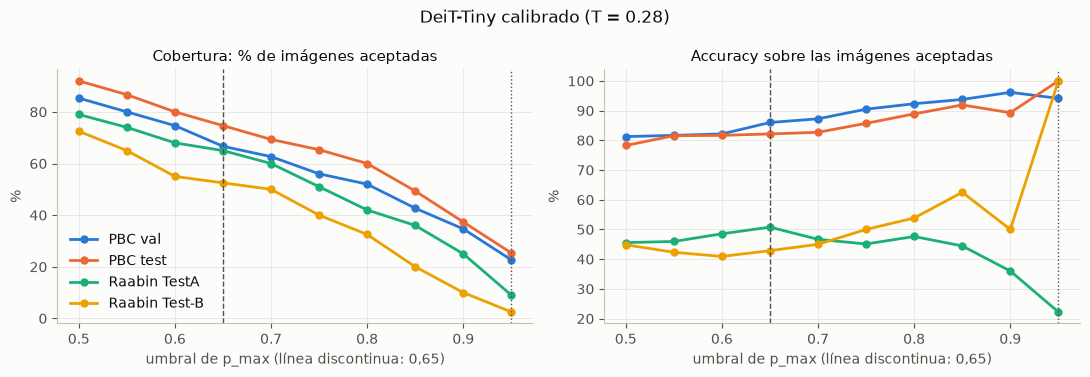

In [19]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for (ds, t), color in zip(TABLAS_UMBRAL.items(), COLORES):
    a1.plot(t.index, t['cobertura (%)'], marker='o', ms=5, color=color, label=ETIQUETA_DS[ds])
    a2.plot(t.index, t['accuracy cubierta (%)'], marker='o', ms=5, color=color, label=ETIQUETA_DS[ds])
for a in (a1, a2):
    a.axvline(UMBRAL_APP, color='#52514e', ls='--', lw=1)
    if UMBRAL_FINAL != UMBRAL_APP:
        a.axvline(UMBRAL_FINAL, color='#52514e', ls=':', lw=1)
    a.set_xlabel('umbral de p_max (línea discontinua: 0,65)')
a1.set_title('Cobertura: % de imágenes aceptadas'); a1.set_ylabel('%')
a2.set_title('Accuracy sobre las imágenes aceptadas'); a2.set_ylabel('%')
a1.legend(loc='lower left')
fig.suptitle(f'{NOMBRE[MODELO_FINAL]} calibrado (T = {TEMPERATURA:.2f})')
fig.tight_layout()
fig.savefig(OUT / 'figuras' / 'umbral_confianza.png', dpi=150)
plt.show()

## 9. Explicabilidad con Grad-CAM

Modelo final, 2 aciertos y 1 error por clase (elegidos al azar con semilla fija). El mapa se calcula para la
clase **predicha**. La probabilidad del título está calibrada.

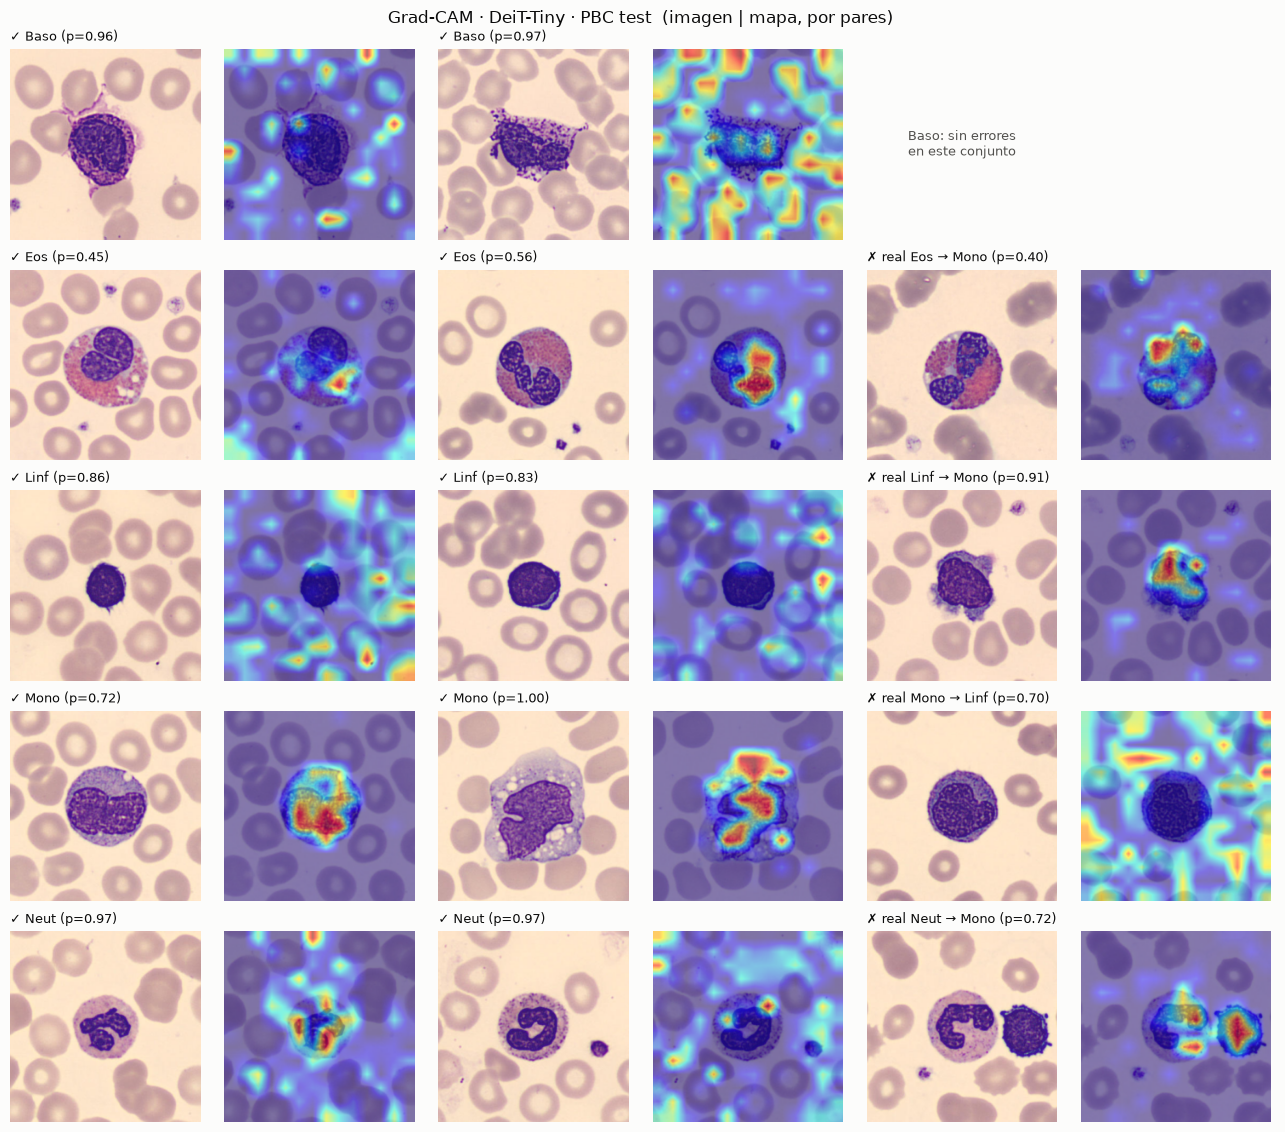

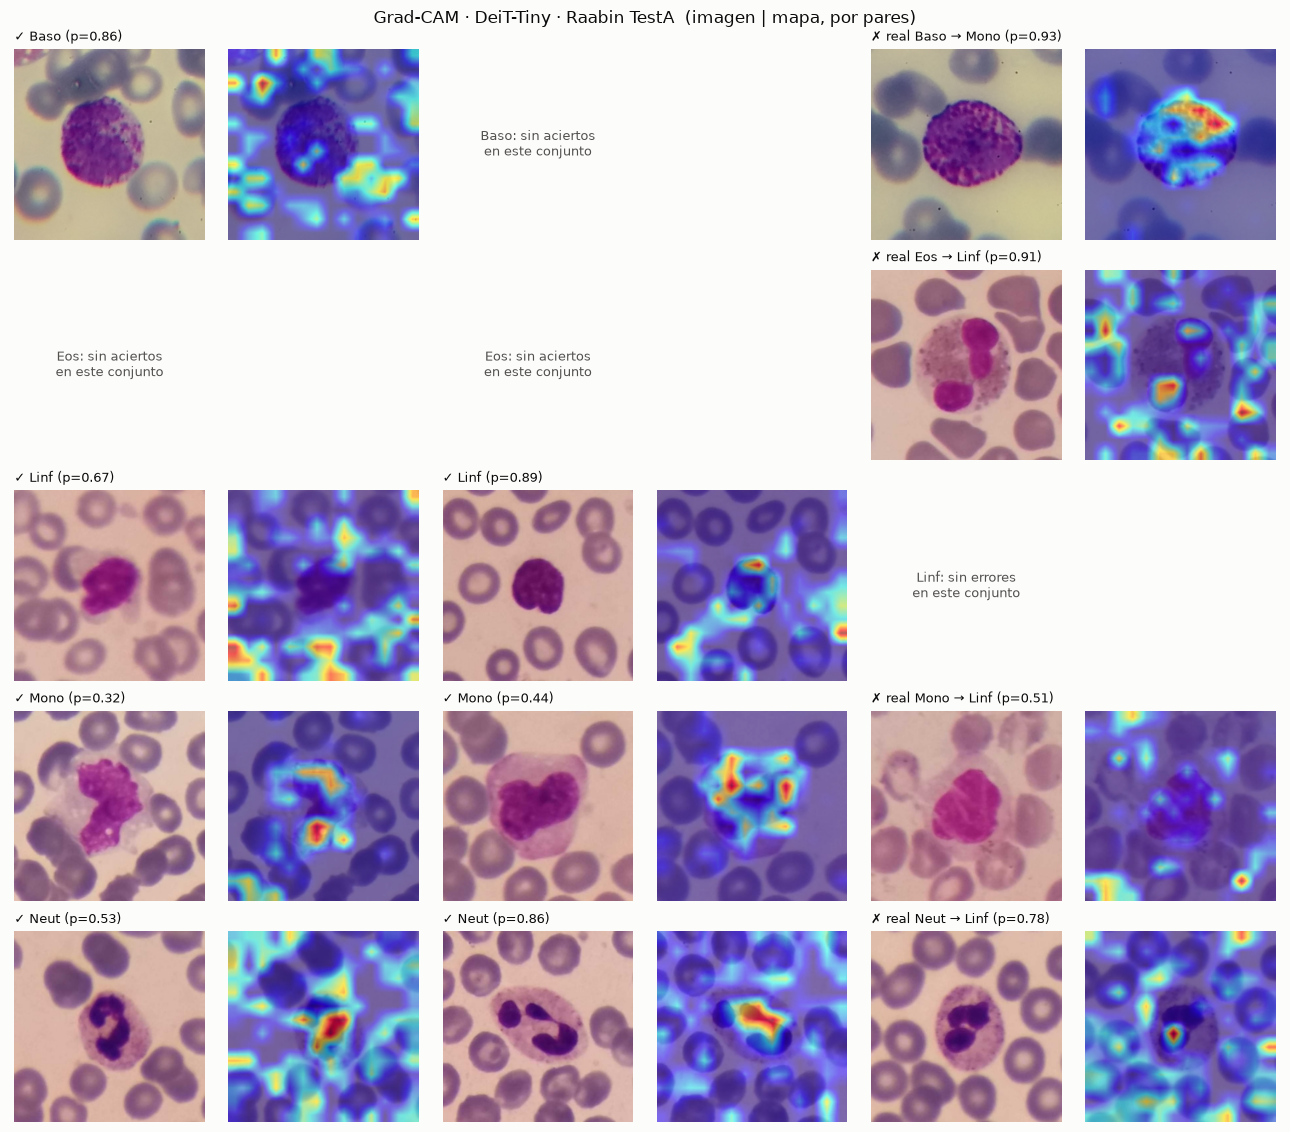

In [20]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

def capa_objetivo(model, nombre):
    return {'mobilenetv2': lambda: model.conv_head, 'resnet18': lambda: model.layer4[-1],
            'deit_tiny': lambda: model.blocks[-1].norm1}[nombre]()

def reshape_vit(t, lado=TAM // 16):
    r = t[:, 1:, :].reshape(t.size(0), lado, lado, t.size(2))  # quita el token CLS
    return r.permute(0, 3, 1, 2)

def figura_gradcam(df, logits, y, titulo, archivo):
    model = cargar_modelo(MODELO_FINAL).to(DEVICE)
    for p in model.parameters():
        p.requires_grad_(True)
    rng = np.random.default_rng(SEMILLA)
    probs = softmax(np.asarray(logits) / TEMPERATURA); pred = probs.argmax(1)
    fig, axes = plt.subplots(len(CLASES), 6, figsize=(13, 11.5))
    resumen = {}
    with GradCAM(model=model, target_layers=[capa_objetivo(model, MODELO_FINAL)],
                 reshape_transform=reshape_vit if MODELO_FINAL == 'deit_tiny' else None) as cam:
        for k, clase in enumerate(CLASES):
            aciertos = np.where((y == k) & (pred == k))[0]
            errores = np.where((y == k) & (pred != k))[0]
            casos = [('acierto', i) for i in rng.choice(aciertos, min(2, len(aciertos)), replace=False)]
            casos += [None] * (2 - len(casos))
            casos += [('error', i) for i in rng.choice(errores, min(1, len(errores)), replace=False)] or [None]
            resumen[clase] = {'aciertos_mostrados': sum(c is not None and c[0] == 'acierto' for c in casos),
                              'errores_disponibles': int(len(errores))}
            for c, caso in enumerate(casos):
                ax_img, ax_cam = axes[k, 2 * c], axes[k, 2 * c + 1]
                ax_img.axis('off'); ax_cam.axis('off')
                if caso is None:
                    ax_img.text(0.5, 0.5, f'{CORTO[clase]}: sin {"errores" if c == 2 else "aciertos"}\nen este conjunto',
                                ha='center', va='center', fontsize=9, color='#52514e', transform=ax_img.transAxes)
                    continue
                tipo, i = caso
                with Image.open(df.ruta.iloc[i]) as im:
                    img = im.convert('RGB')
                rgb = np.asarray(img.resize((TAM, TAM), Image.BILINEAR), dtype=np.float32) / 255.0
                mapa = cam(input_tensor=tf_eval(img).unsqueeze(0).to(DEVICE),
                           targets=[ClassifierOutputTarget(int(pred[i]))])[0]
                ax_img.imshow(rgb)
                ax_cam.imshow(show_cam_on_image(rgb, mapa, use_rgb=True))
                etiqueta = (f'✓ {CORTO[clase]} (p={probs[i].max():.2f})' if tipo == 'acierto'
                            else f'✗ real {CORTO[clase]} → {CORTO[CLASES[pred[i]]]} (p={probs[i].max():.2f})')
                ax_img.set_title(etiqueta, fontsize=9, loc='left')
    fig.suptitle(f'Grad-CAM · {NOMBRE[MODELO_FINAL]} · {titulo}  (imagen | mapa, por pares)')
    fig.tight_layout()
    fig.savefig(OUT / 'figuras' / archivo, dpi=130)
    plt.show()
    del model, cam; liberar()
    return resumen

GRADCAM = {
    'test_pbc': figura_gradcam(test_df, *LF['test_pbc'], 'PBC test', 'gradcam_pbc_test.png'),
    'raabin_testA': figura_gradcam(df_ra, *LF['raabin_testA'], 'Raabin TestA', 'gradcam_raabin_testA.png'),
}

## 10. Regla de salud

Reglas sobre los conteos por clase de un frotis:
- `n_total < 100` → **conteo insuficiente** (no se evalúa lo demás).
- `% neutrófilos > 75 %` → **neutrofilia relativa**.
- `% linfocitos < 20 %` → **linfopenia relativa**.

Es un ejercicio educativo, no una interpretación clínica.

In [21]:
def regla_salud(conteos):
    desconocidas = set(conteos) - set(CLASES)
    if desconocidas:
        raise ValueError(f'Clases desconocidas: {desconocidas}')
    n = sum(conteos.values())
    pct = {c: (100 * conteos.get(c, 0) / n if n else 0.0) for c in CLASES}
    if n < 100:
        return {'n_total': n, 'porcentajes': pct, 'alertas': ['conteo insuficiente']}
    alertas = []
    if pct['neutrophil'] > 75:
        alertas.append('neutrofilia relativa')
    if pct['lymphocyte'] < 20:
        alertas.append('linfopenia relativa')
    return {'n_total': n, 'porcentajes': pct, 'alertas': alertas}

def conteo(neu, lin, mon, eos, bas):
    return dict(neutrophil=neu, lymphocyte=lin, monocyte=mon, eosinophil=eos, basophil=bas)

CASOS = [
    ('menos de 100 células',            conteo(30, 15, 3, 1, 1),  ['conteo insuficiente']),
    ('99 células (límite)',             conteo(60, 30, 6, 2, 1),  ['conteo insuficiente']),
    ('frotis normal (100 células)',     conteo(60, 30, 6, 3, 1),  []),
    ('neutrofilia y linfopenia',        conteo(80, 12, 5, 2, 1),  ['neutrofilia relativa', 'linfopenia relativa']),
    ('solo linfopenia',                 conteo(70, 15, 10, 4, 1), ['linfopenia relativa']),
    ('límites exactos 75 % y 20 %',     conteo(150, 40, 6, 3, 1), []),
    ('justo por encima de 75 %',        conteo(151, 40, 5, 3, 1), ['neutrofilia relativa']),
]
filas = []
for desc, c, esperado in CASOS:
    r = regla_salud(c)
    assert r['alertas'] == esperado, (desc, r['alertas'], esperado)
    filas.append({'caso': desc, 'n': r['n_total'], '% neutr.': round(r['porcentajes']['neutrophil'], 1),
                  '% linf.': round(r['porcentajes']['lymphocyte'], 1), 'alertas': ', '.join(r['alertas']) or '—'})
display(pd.DataFrame(filas))
print(f'Los {len(CASOS)} casos sintéticos dan el resultado esperado.')

,caso,n,% neutr.,% linf.,alertas
0,menos de 100 células,50,60.0,30.0,conteo insuficiente
1,99 células (límite),99,60.6,30.3,conteo insuficiente
2,frotis normal (100 células),100,60.0,30.0,—
3,neutrofilia y linfopenia,100,80.0,12.0,"neutrofilia relativa, linfopenia relativa"
4,solo linfopenia,100,70.0,15.0,linfopenia relativa
5,límites exactos 75 % y 20 %,200,75.0,20.0,—
6,justo por encima de 75 %,200,75.5,20.0,neutrofilia relativa


Los 7 casos sintéticos dan el resultado esperado.


In [22]:
# Lote de 100 predicciones reales del test de PBC
lg, y = LF['test_pbc']
idx = np.random.default_rng(SEMILLA).choice(len(y), min(100, len(y)), replace=False)
p = softmax(lg[idx] / TEMPERATURA); pred = p.argmax(1)
conteo_pred = {c: int((pred == k).sum()) for k, c in enumerate(CLASES)}
conteo_real = {c: int((y[idx] == k).sum()) for k, c in enumerate(CLASES)}
a_revision = int((p.max(1) < UMBRAL_FINAL).sum())

SALUD_REAL = {'n_lote': int(len(idx)), 'segun_prediccion': regla_salud(conteo_pred),
              'segun_etiqueta_real': regla_salud(conteo_real), 'imagenes_a_revision_manual': a_revision}
display(pd.DataFrame({'predicho': conteo_pred, 'real': conteo_real}).T)
print('Alertas con las predicciones:', SALUD_REAL['segun_prediccion']['alertas'] or 'ninguna')
print('Alertas con las etiquetas reales:', SALUD_REAL['segun_etiqueta_real']['alertas'] or 'ninguna')
print(f'Imágenes del lote que irían a revisión manual (p_max < {UMBRAL_FINAL}): {a_revision}')
print('Nota: PBC no reproduce la proporción de un frotis real (se recogieron células por tipo), así que las alertas '
      'de este lote reflejan la composición del dataset, no a un paciente.')

,basophil,eosinophil,lymphocyte,monocyte,neutrophil
predicho,16,5,16,19,19
real,15,15,15,15,15


Alertas con las predicciones: ['conteo insuficiente']
Alertas con las etiquetas reales: ['conteo insuficiente']
Imágenes del lote que irían a revisión manual (p_max < 0.95): 56
Nota: PBC no reproduce la proporción de un frotis real (se recogieron células por tipo), así que las alertas de este lote reflejan la composición del dataset, no a un paciente.


## 11. Exportación a ONNX (y TFLite opcional)

ONNX opset 17, entrada `input` `[1, 3, 224, 224]`, salida `logits` `[1, 5]` (sin softmax: la app aplica
`softmax(logits / T)`). Prueba de paridad PyTorch vs ONNX Runtime en 50 imágenes del test.

In [23]:
model = cargar_modelo(MODELO_FINAL).cpu().eval()
RUTA_ONNX = OUT / 'model.onnx'
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    torch.onnx.export(model, torch.randn(1, 3, TAM, TAM), str(RUTA_ONNX), opset_version=17,
                      input_names=['input'], output_names=['logits'], dynamo=False)
modelo_onnx = onnx.load(str(RUTA_ONNX))
onnx.checker.check_model(modelo_onnx)
forma = lambda v: [d.dim_value for d in v.type.tensor_type.shape.dim]
print(f'ONNX: opset {modelo_onnx.opset_import[0].version} | entrada {forma(modelo_onnx.graph.input[0])} | '
      f'salida {forma(modelo_onnx.graph.output[0])} | {os.path.getsize(RUTA_ONNX) / 1024**2:.2f} MB')

sesion = ort.InferenceSession(str(RUTA_ONNX), providers=['CPUExecutionProvider'])
muestra = test_df.sample(min(50, len(test_df)), random_state=SEMILLA)
difs, coinciden = [], 0
with torch.inference_mode():
    for ruta in muestra.ruta:
        with Image.open(ruta) as im:
            x = tf_eval(im.convert('RGB')).unsqueeze(0)
        a = model(x).numpy()
        b = sesion.run(['logits'], {'input': x.numpy()})[0]
        difs.append(float(np.abs(a - b).max())); coinciden += int(a.argmax() == b.argmax())
x = np.random.randn(1, 3, TAM, TAM).astype(np.float32)
for _ in range(10):
    sesion.run(['logits'], {'input': x})
t = time.perf_counter()
for _ in range(N_TIEMPO):
    sesion.run(['logits'], {'input': x})
ms_ort = (time.perf_counter() - t) / N_TIEMPO * 1000

ONNX_INFO = dict(ruta=RUTA_ONNX.as_posix(), opset=17, tamano_mb=os.path.getsize(RUTA_ONNX) / 1024**2,
                 paridad_n=len(difs), paridad_dif_max=max(difs), paridad_argmax_coincide=coinciden,
                 ms_cpu_onnxruntime=ms_ort)
print(f'Paridad en {len(difs)} imágenes: diferencia máxima {max(difs):.2e} | misma clase en {coinciden}/{len(difs)} | '
      f'ONNX Runtime CPU: {ms_ort:.2f} ms/imagen')
assert max(difs) < 1e-4, 'La diferencia PyTorch vs ONNX supera 1e-4'
del model; liberar()

ONNX: opset 17 | entrada [1, 3, 224, 224] | salida [1, 5] | 21.17 MB


Paridad en 50 imágenes: diferencia máxima 9.18e-06 | misma clase en 50/50 | ONNX Runtime CPU: 34.99 ms/imagen


In [24]:
with open(OUT / 'labels.json', 'w', encoding='utf-8') as f:
    json.dump(CLASES, f, indent=2)

PREPROCESAMIENTO.update({
    'temperature': TEMPERATURA,
    'umbral_revision_manual': UMBRAL_FINAL,
    'postprocesamiento': 'p = softmax(logits / temperature); si max(p) < umbral_revision_manual → "revisión manual"',
    'modelo': NOMBRE[MODELO_FINAL],
})
with open(OUT / 'preprocessing.json', 'w', encoding='utf-8') as f:
    json.dump(PREPROCESAMIENTO, f, indent=2, ensure_ascii=False)
print(json.dumps(PREPROCESAMIENTO, indent=2, ensure_ascii=False))

{
  "input_name": "input",
  "input_shape": [
    1,
    3,
    224,
    224
  ],
  "layout": "NCHW",
  "dtype": "float32",
  "color": "RGB",
  "resize": {
    "size": [
      224,
      224
    ],
    "mode": "directo, sin recorte ni relleno",
    "interpolation": "bilinear"
  },
  "scale": "pixel / 255.0 → [0, 1]",
  "mean": [
    0.485,
    0.456,
    0.406
  ],
  "std": [
    0.229,
    0.224,
    0.225
  ],
  "formula": "(pixel / 255 - mean[c]) / std[c]",
  "output_name": "logits",
  "output_shape": [
    1,
    5
  ],
  "labels": [
    "basophil",
    "eosinophil",
    "lymphocyte",
    "monocyte",
    "neutrophil"
  ],
  "aumento_solo_entrenamiento": {
    "flip_horizontal": 0.5,
    "flip_vertical": 0.5,
    "rotacion_grados": 20,
    "color_jitter": {
      "brightness": 0.2,
      "contrast": 0.2,
      "saturation": 0.2,
      "hue": 0.02
    }
  },
  "temperature": 0.2818236680564737,
  "umbral_revision_manual": 0.95,
  "postprocesamiento": "p = softmax(logits / temperature

In [25]:
# TFLite opcional: solo si hay un conversor instalado (no se instala nada desde aquí)
try:
    import onnx2tf
    import tensorflow as tf
except ImportError as e:
    TFLITE = {'estado': 'omitido', 'motivo': f'falta el paquete {e.name}'}
    print(f'TFLite omitido: no está instalado {e.name}. Convertir a TFLite requiere TensorFlow (vía onnx2tf) o '
          'ai-edge-torch, que traen sus propias versiones de numpy/protobuf y pueden romper este entorno; '
          'ai-edge-torch, además, se distribuye para Linux (en Windows haría falta WSL). '
          'Se deja ONNX como formato principal: ONNX Runtime tiene paquete oficial para Android (Kotlin/Java) '
          'y hay paquetes de Flutter que lo usan.')
else:
    try:
        carpeta = OUT / 'tflite'
        onnx2tf.convert(input_onnx_file_path=str(RUTA_ONNX), output_folder_path=str(carpeta),
                        keep_ncw_or_nchw_or_ncdhw_input_names=['input'], non_verbose=True)
        ruta_tfl = next(carpeta.glob('*float32.tflite'))
        interp = tf.lite.Interpreter(model_path=str(ruta_tfl)); interp.allocate_tensors()
        ent, sal = interp.get_input_details()[0], interp.get_output_details()[0]
        difs_tfl = []
        for ruta in muestra.ruta:
            with Image.open(ruta) as im:
                x = tf_eval(im.convert('RGB')).unsqueeze(0).numpy()
            interp.set_tensor(ent['index'], x); interp.invoke()
            difs_tfl.append(float(np.abs(interp.get_tensor(sal['index']) - sesion.run(['logits'], {'input': x})[0]).max()))
        TFLITE = {'estado': 'ok', 'ruta': ruta_tfl.as_posix(), 'paridad_dif_max_vs_onnx': max(difs_tfl)}
        print(f'TFLite: {ruta_tfl} | diferencia máxima vs ONNX: {max(difs_tfl):.2e}')
    except Exception as e:
        TFLITE = {'estado': 'fallido', 'motivo': repr(e)}
        print('La conversión a TFLite falló; se mantiene ONNX como formato principal.', repr(e))

TFLite omitido: no está instalado onnx2tf. Convertir a TFLite requiere TensorFlow (vía onnx2tf) o ai-edge-torch, que traen sus propias versiones de numpy/protobuf y pueden romper este entorno; ai-edge-torch, además, se distribuye para Linux (en Windows haría falta WSL). Se deja ONNX como formato principal: ONNX Runtime tiene paquete oficial para Android (Kotlin/Java) y hay paquetes de Flutter que lo usan.


## 12. Entregables y conclusiones

In [26]:
if MODO_RAPIDO:
    print('⚠️ MODO_RAPIDO: las cifras de abajo solo comprueban que el flujo funciona; no son resultados válidos.\n')

print('Tabla 1 · Comparación de los modelos (PBC test y Raabin)')
cols = ['parámetros (M)', 'tamaño (MB)', 'PBC acc (%)', 'PBC F1 macro (%)', 'PBC AUC', 'TestA acc (%)',
        'TestA F1 macro (%)', 'caída F1 macro PBC→TestA (pts)', 'Test-B acc (%)', 'GPU ms/img', 'CPU ms/img']
display(TABLA_MODELOS[cols].round(2))

mf = METRICAS[MODELO_FINAL]
LITERATURA = pd.DataFrame([
    dict(trabajo='Acevedo et al., 2019', modelo='VGG-16 / Inception-v3', datos='PBC', clases=8, accuracy=96.2,
         notas='Mismo dataset, pero 8 clases (incluye IG, eritroblastos y plaquetas) y otra partición: no es directa.'),
    dict(trabajo='Cheuque et al., 2022', modelo='Faster R-CNN + MobileNet', datos='del artículo', clases=4, accuracy=98.4,
         notas='4 clases sin basófilos, detección + clasificación y otros datos/partición: no es directa.'),
    dict(trabajo='Katar y Yildirim, 2023', modelo='ViT (+ Score-CAM)', datos='del artículo', clases=5, accuracy=99.40,
         notas='Mismas 5 clases, pero otros datos/partición: comparable solo en orden de magnitud.'),
    dict(trabajo='Yin et al., 2023', modelo='Swin Transformer', datos='del artículo', clases=None, accuracy=99.1,
         notas='Otros datos/partición. Monocitos: clase más débil (93,8 %).'),
    dict(trabajo='Yin et al., 2023', modelo='ResNet', datos='del artículo', clases=None, accuracy=95.2,
         notas='Línea base del mismo artículo; otros datos/partición.'),
] + [
    dict(trabajo='HemoLearn (este notebook)', modelo=NOMBRE[n] + (' ★ app' if n == MODELO_FINAL else ''),
         datos='PBC test (15 %)', clases=5, accuracy=round(100 * METRICAS[n]['test_pbc']['accuracy'], 2),
         notas=(f'F1 macro {100 * METRICAS[n]["test_pbc"]["f1_macro"]:.2f} %. En Raabin TestA (otro centro): '
                f'acc {100 * METRICAS[n]["raabin_testA"]["accuracy"]:.2f} %, F1 macro {100 * METRICAS[n]["raabin_testA"]["f1_macro"]:.2f} %.'
                + (' Modo rápido: no válido.' if MODO_RAPIDO else '')))
    for n in METRICAS
])
LITERATURA['clases'] = LITERATURA['clases'].astype('Int64')
LITERATURA.to_csv(OUT / 'tabla_literatura.csv', index=False)
print('Tabla 2 · Comparación con la literatura (accuracy en %)')
display(LITERATURA)

⚠️ MODO_RAPIDO: las cifras de abajo solo comprueban que el flujo funciona; no son resultados válidos.

Tabla 1 · Comparación de los modelos (PBC test y Raabin)


,parámetros (M),tamaño (MB),PBC acc (%),PBC F1 macro (%),PBC AUC,TestA acc (%),TestA F1 macro (%),caída F1 macro PBC→TestA (pts),Test-B acc (%),GPU ms/img,CPU ms/img
modelo,,,,,,,,,,,
MobileNetV2,2.23,8.73,48.00,47.72,0.87,30.0,23.73,24.00,5.0,46.08,47.10
ResNet18,11.18,42.72,65.33,61.86,0.95,45.0,40.10,21.76,42.5,21.49,62.61
DeiT-Tiny,5.53,21.12,77.33,75.31,0.94,40.0,32.31,43.00,45.0,41.88,58.96


Tabla 2 · Comparación con la literatura (accuracy en %)


,trabajo,modelo,datos,clases,accuracy,notas
0,"Acevedo et al., 2019",VGG-16 / Inception-v3,PBC,8,96.20,"Mismo dataset, pero 8 clases (incluye IG, erit..."
1,"Cheuque et al., 2022",Faster R-CNN + MobileNet,del artículo,4,98.40,"4 clases sin basófilos, detección + clasificac..."
2,"Katar y Yildirim, 2023",ViT (+ Score-CAM),del artículo,5,99.40,"Mismas 5 clases, pero otros datos/partición: c..."
3,"Yin et al., 2023",Swin Transformer,del artículo,<NA>,99.10,Otros datos/partición. Monocitos: clase más dé...
4,"Yin et al., 2023",ResNet,del artículo,<NA>,95.20,Línea base del mismo artículo; otros datos/par...
5,HemoLearn (este notebook),MobileNetV2,PBC test (15 %),5,48.00,F1 macro 47.72 %. En Raabin TestA (otro centro...
6,HemoLearn (este notebook),ResNet18,PBC test (15 %),5,65.33,F1 macro 61.86 %. En Raabin TestA (otro centro...
7,HemoLearn (este notebook),DeiT-Tiny ★ app,PBC test (15 %),5,77.33,F1 macro 75.31 %. En Raabin TestA (otro centro...


In [27]:
def limpiar(o):
    if isinstance(o, dict):
        return {str(k): limpiar(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [limpiar(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.ndarray):
        return limpiar(o.tolist())
    if isinstance(o, Path):
        return o.as_posix()
    return o

METRICS_JSON = {
    'modo_rapido': MODO_RAPIDO,
    'fecha': datetime.now().isoformat(timespec='seconds'),
    'entorno': {'python': platform.python_version(), 'torch': torch.__version__, 'timm': timm.__version__,
                'onnxruntime': ort.__version__, 'dispositivo': torch.cuda.get_device_name(0) if USA_AMP else 'cpu'},
    'datos': {'pbc': RUTA_PBC.as_posix(), 'raabin_principal': RUTA_RAABIN_A.as_posix(),
              'raabin_secundario': RUTA_RAABIN_B.as_posix(), 'conteos': conteo_particiones.to_dict()},
    'configuracion': {'semilla': SEMILLA, 'epocas_etapa1': EPOCAS_E1, 'epocas_etapa2': EPOCAS_E2, 'paciencia': PACIENCIA,
                      'lr_etapa1': LR_E1, 'lr_etapa2': LR_E2, 'pesos_clase': dict(zip(CLASES, PESOS.tolist()))},
    'labels': CLASES,
    'modelo_final': MODELO_FINAL,
    'criterio_seleccion': f'modelo más ligero con F1 macro val ≥ mejor − {TOLERANCIA_F1}',
    'modelos': {n: {'timm': MODELOS[n]['timm'],
                    'entrenamiento': {k: v for k, v in RESULTADOS_ENT[n].items() if k != 'historial'},
                    'historial': RESULTADOS_ENT[n]['historial'],
                    'eficiencia': EFICIENCIA[n],
                    'metricas': METRICAS[n]} for n in METRICAS},
    'calibracion': {'temperatura': TEMPERATURA, 'por_conjunto': CALIBRACION},
    'umbral': {'umbral_app': UMBRAL_APP, 'umbral_recomendado': UMBRAL_FINAL, 'objetivo_accuracy_val': OBJETIVO_ACC_UMBRAL,
               'justificacion': razon, 'tablas': {k: v.reset_index().to_dict('records') for k, v in TABLAS_UMBRAL.items()}},
    'gradcam': GRADCAM,
    'regla_salud': {'casos_sinteticos_ok': len(CASOS), 'lote_real': SALUD_REAL},
    'onnx': ONNX_INFO,
    'tflite': TFLITE,
}
with open(OUT / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(limpiar(METRICS_JSON), f, indent=2, ensure_ascii=False)
print(f'metrics.json guardado ({os.path.getsize(OUT / "metrics.json") / 1024:.0f} KB)')

metrics.json guardado (51 KB)


In [28]:
# Párrafo de conclusiones generado con las cifras de esta ejecución
n = MODELO_FINAL
t, a = METRICAS[n]['test_pbc'], METRICAS[n]['raabin_testA']
peor_a = min(a['por_clase'], key=lambda c: a['por_clase'][c]['f1'])
mejor_ext = max(METRICAS, key=lambda m: METRICAS[m]['raabin_testA']['f1_macro'])
gap_val = 100 * (RESULTADOS_ENT[MEJOR_VAL]['f1_val_mejor'] - RESULTADOS_ENT[n]['f1_val_mejor'])
otros = [m for m in METRICAS if m != n]

partes = [
    f'Para la app se elige **{NOMBRE[n]}**. ',
    (f'Obtuvo el mejor F1 macro en la validación de PBC ({100 * RESULTADOS_ENT[n]["f1_val_mejor"]:.2f} %)'
     if n == MEJOR_VAL else
     f'Su F1 macro en validación de PBC ({100 * RESULTADOS_ENT[n]["f1_val_mejor"]:.2f} %) quedó a {gap_val:.2f} puntos '
     f'del mejor ({NOMBRE[MEJOR_VAL]}), dentro de la tolerancia fijada de {100 * TOLERANCIA_F1:.0f} punto'),
    (f'; entre los modelos a ≤{100 * TOLERANCIA_F1:.0f} punto del mejor, es el más ligero' if otros else ''),
    f' ({EFICIENCIA[n]["parametros"] / 1e6:.2f} M parámetros, {ONNX_INFO["tamano_mb"]:.1f} MB en ONNX, '
    f'{ONNX_INFO["ms_cpu_onnxruntime"]:.1f} ms por imagen en CPU con ONNX Runtime). ',
    f'En el test de PBC alcanza una accuracy de {100 * t["accuracy"]:.2f} % y un F1 macro de {100 * t["f1_macro"]:.2f} %; '
    f'en la validación externa con Raabin TestA, el F1 macro es {100 * a["f1_macro"]:.2f} % '
    f'(caída de {100 * (t["f1_macro"] - a["f1_macro"]):.1f} puntos), y la clase más débil es {peor_a} '
    f'(F1 {100 * a["por_clase"][peor_a]["f1"]:.1f} %). ',
]
if mejor_ext != n:
    partes.append(f'{NOMBRE[mejor_ext]} generalizó mejor a Raabin (F1 macro '
                  f'{100 * METRICAS[mejor_ext]["raabin_testA"]["f1_macro"]:.2f} %), pero esa información no se usó para '
                  f'elegir, porque Raabin se reserva para la evaluación final. ')
partes.append(
    f'Tras calibrar (T = {TEMPERATURA:.2f}), el umbral de revisión manual recomendado es {UMBRAL_FINAL}: {razon} '
    f'El modelo exportado a ONNX reproduce a PyTorch con una diferencia máxima de {ONNX_INFO["paridad_dif_max"]:.1e}. '
    'La caída en Raabin confirma que el cambio de centro (tinción y cámara) es la principal limitación, por lo que la app '
    'debe presentarse como herramienta educativa y no de diagnóstico.')
CONCLUSIONES = ''.join(partes)
if MODO_RAPIDO:
    CONCLUSIONES = '**[MODO RÁPIDO: cifras no válidas]** ' + CONCLUSIONES
with open(OUT / 'conclusiones.md', 'w', encoding='utf-8') as f:
    f.write('# Conclusiones\n\n' + CONCLUSIONES + '\n')
print(CONCLUSIONES)

print('\nArchivos en', OUT.as_posix())
for p in sorted(OUT.rglob('*')):
    if p.is_file() and 'splits' not in p.parts:
        print(f'  {p.relative_to(OUT).as_posix():45s} {p.stat().st_size / 1024:9.1f} KB')

**[MODO RÁPIDO: cifras no válidas]** Para la app se elige **DeiT-Tiny**. Obtuvo el mejor F1 macro en la validación de PBC (77.36 %); entre los modelos a ≤1 punto del mejor, es el más ligero (5.53 M parámetros, 21.2 MB en ONNX, 35.0 ms por imagen en CPU con ONNX Runtime). En el test de PBC alcanza una accuracy de 77.33 % y un F1 macro de 75.31 %; en la validación externa con Raabin TestA, el F1 macro es 32.31 % (caída de 43.0 puntos), y la clase más débil es eosinophil (F1 0.0 %). ResNet18 generalizó mejor a Raabin (F1 macro 40.10 %), pero esa información no se usó para elegir, porque Raabin se reserva para la evaluación final. Tras calibrar (T = 0.28), el umbral de revisión manual recomendado es 0.95: Ningún umbral de la rejilla alcanza 99% en validación; se propone el más estricto (0.95). El modelo exportado a ONNX reproduce a PyTorch con una diferencia máxima de 9.2e-06. La caída en Raabin confirma que el cambio de centro (tinción y cámara) es la principal limitación, por lo que la a